In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import polars as pl
import matplotlib.pyplot as plt
import config

### Ячейка 2. Загрузка данных и расчёт спреда
 1) Читаем готовые 5m-свечи пары ETH/BTC из parquet (их создал prepare.py).
 2) Добавляем столбец time: open_time из миллисекунд -> обычная дата и время.
 3) Добавляем столбец spread = ln(ETH) - ln(BTC) — показатель того, насколько ETH дорог или дёшев относительно BTC. На нём работает стратегия.


In [2]:
df = pl.read_parquet(config.PROCESSED_DIR / "pair_5m.parquet")

df = df.with_columns(
    pl.from_epoch("open_time", time_unit="ms").alias("time"),          # мс -> дата и время
    (pl.col("close_a").log() - pl.col("close_b").log()).alias("spread"),     # s = ln(ETH) - ln(BTC)
)
df.select("time", "close_a", "close_b", "spread").head()

time,close_a,close_b,spread
datetime[μs],f64,f64,f64
2024-10-01 00:00:00,2602.19,63315.2,-3.191772
2024-10-01 00:05:00,2606.4,63317.0,-3.190184
2024-10-01 00:10:00,2605.77,63193.5,-3.188473
2024-10-01 00:15:00,2599.28,63075.5,-3.189098
2024-10-01 00:20:00,2600.84,63113.0,-3.189092


### График спреда за 2 года
Красная линия — граница: слева год подбора параметров, справа год проверки.

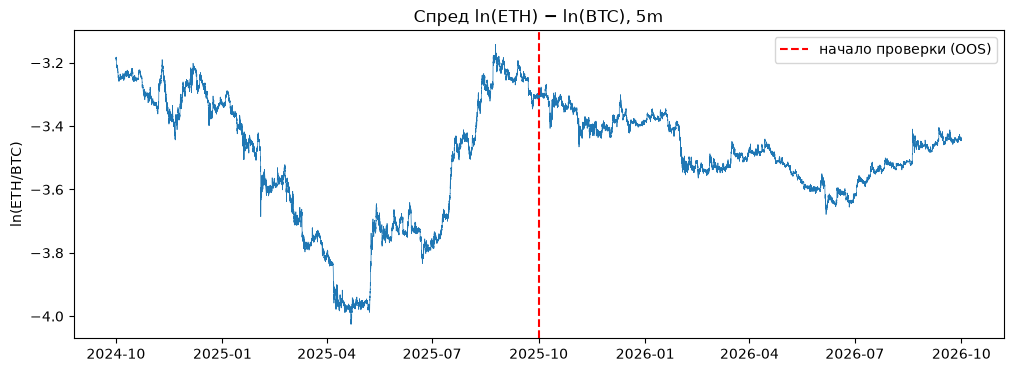

In [3]:
oos = pl.Series([config.OOS_START]).str.to_datetime()[0]   # дата начала проверки

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["time"], df["spread"], linewidth=0.5)
ax.axvline(oos, color="red", linestyle="--", label="начало проверки (OOS)")
ax.set_title("Спред ln(ETH) − ln(BTC), 5m")
ax.set_ylabel("ln(ETH/BTC)")
ax.legend()
fig.savefig(config.FIGURES_DIR / "01_spread.png", dpi=150, bbox_inches="tight")
plt.show()

### Дневная волатильность спреда
На сколько процентов в день обычно меняется отношение ETH/BTC. В плане была прикидка 2.5%.

In [4]:
DAY_MS = 24 * 60 * 60 * 1000   # сутки в миллисекундах

daily = (
    df.with_columns((pl.col("open_time") // DAY_MS).alias("day"))   # номер дня
    .group_by("day", maintain_order=True)
    .agg(pl.col("spread").last())                                     # спред на конец дня
)
daily_change = daily["spread"].diff().drop_nulls()                   # изменение за день

print("дней:", daily.height)
print("дневная волатильность спреда:", round(daily_change.std() * 100, 2), "%")

дней: 730
дневная волатильность спреда: 2.11 %


### Год 1 и год 2
Насколько отличаются период подбора и период проверки.

In [5]:
for name, part in [("год 1 (подбор)", df.filter(pl.col("time") < oos)),
                   ("год 2 (проверка)", df.filter(pl.col("time") >= oos))]:
    d = (part.with_columns((pl.col("open_time") // DAY_MS).alias("day"))
             .group_by("day", maintain_order=True).agg(pl.col("spread").last()))
    print(name, "| волатильность:", round(d["spread"].diff().drop_nulls().std() * 100, 2), "%",
          "| спред от", round(part["spread"].min(), 3), "до", round(part["spread"].max(), 3))

год 1 (подбор) | волатильность: 2.55 % | спред от -4.026 до -3.142
год 2 (проверка) | волатильность: 1.56 % | спред от -3.679 до -3.268
